# Day 12: LLM Engineering – Prompting, Structured Output & Local Models

**Goal:** control LLMs reliably before building agents.
1. Call a **hosted LLM API** (Google Gemini) and an **open-weight model running locally via Ollama**, recording **latency, tokens and cost**.
2. Solve one task (classifying customer support tickets by **urgency** and **department**) with **zero-shot**, **few-shot** and **chain-of-thought** prompts, and compare accuracy on **50 labelled tickets**.
3. Force **structured output**: a **Pydantic** schema, JSON validation and **automatic retry** when the output fails to parse.
4. **Analysis:** best accuracy-to-cost ratio, and failure cases (hallucinations, format errors).

**Runtime: no GPU needed.** Use the normal CPU runtime (keep your free GPU time for other days). **Runtime → Run all.**
Total time: about 20–30 minutes (most of it is the free-tier rate limit and the local model on CPU).

## 0. Install and settings
**Before running:** get a free Gemini API key from **aistudio.google.com → Get API key**, then in Colab click the **🔑 Secrets** icon (left sidebar) → **Add new secret**, name it `GEMINI_API_KEY`, paste the key and turn on **Notebook access**.
Never paste the key directly into the code or push it to GitHub.

In [1]:
!pip install -q -U google-genai pydantic
!apt-get install -y -qq zstd > /dev/null

import os, re, json, time, subprocess, requests
from typing import Literal
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pydantic import BaseModel, Field, ValidationError

# ---- Settings ----
RUN_HOSTED   = True                 # Gemini (hosted API)
RUN_LOCAL    = True                 # Ollama (open-weight model running in this Colab machine)
LOCAL_MODEL  = "qwen2.5:1.5b"       # small (~1 GB), works on CPU
HOSTED_PREFERRED = ["gemini-2.5-flash", "gemini-2.0-flash", "gemini-flash-latest"]
RPM          = 10                   # free-tier requests per minute limit (keeps us under the limit)
MAX_RETRIES  = 2                    # retries when the output fails validation
# Prices in US$ per 1 million tokens, for the cost estimate. Fill in from the provider's
# current pricing page (the free tier costs $0, but show what the paid tier would cost).
PRICE_PER_M  = {"hosted": {"in": 0.0, "out": 0.0}, "local": {"in": 0.0, "out": 0.0}}

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires google-auth==2.49.0, but you have google-auth 2.62.0 which is incompatible.


## 1. The labelled dataset: 50 support tickets
Short example tickets written for this exercise and labelled by hand (the "gold set").
- **Urgency:** `high` = business stopped, money/security/safety at risk, or a hard deadline within about a day; `medium` = a real problem that needs action but isn't an emergency; `low` = a question, request or feedback with no impact.
- **Department:** `billing`, `technical`, `account`, `shipping`, `general`.

5 extra tickets (not in the test set) are used as the **few-shot examples**.

In [2]:
FEW_SHOT = [
    ("I was charged twice for my subscription this month, please refund the extra payment.", "medium", "billing"),
    ("The app crashes every time I open it and I can't access my files for a client meeting in an hour.", "high", "technical"),
    ("How do I change the email address on my profile?", "low", "account"),
    ("My order hasn't arrived and tracking hasn't updated for 10 days.", "medium", "shipping"),
    ("Do you offer a student discount?", "low", "general"),
]

TICKETS = [
    # billing
    ("Your system charged my card $2,400 instead of $24. I need this reversed today, my rent is due.", "high", "billing"),
    ("Can you send me a copy of last month's invoice for my records?", "low", "billing"),
    ("I cancelled my plan but was still billed this month.", "medium", "billing"),
    ("My payment keeps failing at checkout even though my card works everywhere else.", "medium", "billing"),
    ("What payment methods do you accept?", "low", "billing"),
    ("Fraud alert! There are 15 transactions on my card from your store that I did not make, stop them immediately.", "high", "billing"),
    ("I'd like to switch from monthly to annual billing to save money.", "low", "billing"),
    ("I was promised a 20% discount but it wasn't applied to my bill.", "medium", "billing"),
    ("Please update the company name shown on our invoices.", "low", "billing"),
    ("The refund you approved two weeks ago still hasn't reached my account.", "medium", "billing"),
    # technical
    ("Your entire website is down and none of our 200 employees can work.", "high", "technical"),
    ("The export to PDF button does nothing when I click it.", "medium", "technical"),
    ("The dark mode colours look a bit off on the settings page.", "low", "technical"),
    ("I get 'Error 500' whenever I try to upload a file larger than 10 MB.", "medium", "technical"),
    ("Our production API integration started returning errors 30 minutes ago and customer orders are failing.", "high", "technical"),
    ("It would be nice if the search bar remembered my last few searches.", "low", "technical"),
    ("The mobile app logs me out every few minutes.", "medium", "technical"),
    ("All customer data in our dashboard disappeared after your update this morning!", "high", "technical"),
    ("Pages load a little slowly in the afternoons, about 5 seconds.", "low", "technical"),
    ("Notifications are not being delivered to my phone since yesterday.", "medium", "technical"),
    # account
    ("I think my account was hacked: someone changed my password and is sending messages from it.", "high", "account"),
    ("How do I add a second user to my team account?", "low", "account"),
    ("I can't reset my password, the reset email never arrives.", "medium", "account"),
    ("Please delete my account and all my personal data.", "medium", "account"),
    ("I want to change my username.", "low", "account"),
    ("I'm locked out of my admin account and need to approve payroll before 5 pm today.", "high", "account"),
    ("How can I turn on two-factor authentication?", "low", "account"),
    ("I need to transfer ownership of our team account to my colleague who is taking over.", "low", "account"),
    ("I got an email saying someone just logged into my account from another country, and it wasn't me.", "high", "account"),
    ("Can I merge my two accounts into one?", "low", "account"),
    # shipping
    ("The package arrived damaged and the glass inside is broken.", "medium", "shipping"),
    ("I need to change my delivery address before the order ships tomorrow.", "medium", "shipping"),
    ("Where can I find the tracking number for my order?", "low", "shipping"),
    ("I ordered insulin cooling packs that must arrive by Friday and the delivery is now delayed.", "high", "shipping"),
    ("I received someone else's order instead of mine.", "medium", "shipping"),
    ("Do you ship to Sri Lanka?", "low", "shipping"),
    ("The courier marked my parcel as delivered but it's not here.", "medium", "shipping"),
    ("My wedding dress was supposed to arrive today and the wedding is tomorrow. It's still not here!", "high", "shipping"),
    ("How long does standard delivery usually take?", "low", "shipping"),
    ("Two items from my order are missing from the box.", "medium", "shipping"),
    # general
    ("What are your customer support hours?", "low", "general"),
    ("I just wanted to say your team was very helpful, thank you!", "low", "general"),
    ("Are you hiring for remote positions?", "low", "general"),
    ("Do you have an office in Colombo I can visit?", "low", "general"),
    ("I'd like to give some feedback about your new logo.", "low", "general"),
    ("Is there a partnership programme for resellers?", "low", "general"),
    ("Your support agent was rude to me on the phone yesterday and I want to file a complaint.", "medium", "general"),
    ("Can I get a price quote for 500 licences for my company?", "medium", "general"),
    ("Where can I read your privacy policy?", "low", "general"),
    ("I'm a journalist: can I get a comment on yesterday's outage for an article publishing in one hour?", "high", "general"),
]
gold = pd.DataFrame(TICKETS, columns=["ticket", "urgency", "department"])
print(len(gold), "labelled tickets")
print(gold["urgency"].value_counts().to_dict(), gold["department"].value_counts().to_dict())

50 labelled tickets
{'low': 22, 'medium': 17, 'high': 11} {'billing': 10, 'technical': 10, 'account': 10, 'shipping': 10, 'general': 10}


## 2. Structured output: the Pydantic schema
The schema is the "form" the model must fill in. `Literal[...]` means only those exact values are allowed.
For **chain-of-thought**, the model first writes short `reasoning`, then the labels (reasoning *before* the answer is what makes CoT work).

In [3]:
Urgency = Literal["high", "medium", "low"]
Department = Literal["billing", "technical", "account", "shipping", "general"]

class TicketLabel(BaseModel):
    urgency: Urgency
    department: Department

class TicketLabelCoT(BaseModel):
    reasoning: str = Field(description="1-3 short sentences explaining the decision")
    urgency: Urgency
    department: Department

print(json.dumps(TicketLabel.model_json_schema(), indent=1)[:400], "...")

{
 "properties": {
  "urgency": {
   "enum": [
    "high",
    "medium",
    "low"
   ],
   "title": "Urgency",
   "type": "string"
  },
  "department": {
   "enum": [
    "billing",
    "technical",
    "account",
    "shipping",
    "general"
   ],
   "title": "Department",
   "type": "string"
  }
 },
 "required": [
  "urgency",
  "department"
 ],
 "title": "TicketLabel",
 "type": "object"
} ...


## 3. The three prompting strategies
- **Zero-shot:** instructions + the ticket, no examples.
- **Few-shot:** the same instructions + 5 labelled examples.
- **Chain-of-thought (CoT):** the same instructions + "think step by step" (short reasoning before the answer).

In [4]:
INSTRUCTIONS = """You classify customer support tickets.
Urgency:
- high: business stopped, money/security/safety at risk, or a hard deadline within about a day
- medium: a real problem that needs action, but not an emergency
- low: a question, request or feedback with no real impact
Department: billing, technical, account, shipping or general."""

def zero_shot(t):
    return f"""{INSTRUCTIONS}

Ticket: "{t}"
Return JSON with "urgency" and "department"."""

def few_shot(t):
    ex = "\n".join(f'Ticket: "{x}"\nAnswer: {{"urgency": "{u}", "department": "{d}"}}' for x, u, d in FEW_SHOT)
    return f"""{INSTRUCTIONS}

Examples:
{ex}

Ticket: "{t}"
Return JSON with "urgency" and "department"."""

def chain_of_thought(t):
    return f"""{INSTRUCTIONS}

Ticket: "{t}"
Think step by step: first explain briefly (1-3 sentences) what the customer needs, who handles it and how serious it is.
Return JSON with "reasoning" first, then "urgency" and "department"."""

STRATEGIES = {"zero-shot": (zero_shot, TicketLabel),
              "few-shot": (few_shot, TicketLabel),
              "chain-of-thought": (chain_of_thought, TicketLabelCoT)}
print(few_shot("Example ticket")[:600])

You classify customer support tickets.
Urgency:
- high: business stopped, money/security/safety at risk, or a hard deadline within about a day
- medium: a real problem that needs action, but not an emergency
- low: a question, request or feedback with no real impact
Department: billing, technical, account, shipping or general.

Examples:
Ticket: "I was charged twice for my subscription this month, please refund the extra payment."
Answer: {"urgency": "medium", "department": "billing"}
Ticket: "The app crashes every time I open it and I can't access my files for a client meeting in an hour."
An


## 4. Hosted LLM: Google Gemini
Uses the `google-genai` SDK with **JSON mode + the Pydantic schema**. A small wait between calls keeps us under the free-tier rate limit, and "429 / quota" errors are retried with a pause.
If no API key is found, the notebook falls back to **Colab's built-in Gemini** (no key needed, but it doesn't report token counts, so tokens are estimated as characters ÷ 4).

In [5]:
hosted_mode, hosted_name = None, None
if RUN_HOSTED:
    api_key = None
    try:
        from google.colab import userdata
        api_key = userdata.get("GEMINI_API_KEY")
    except Exception:
        api_key = os.environ.get("GEMINI_API_KEY")

    if api_key:
        from google import genai
        from google.genai import types
        client = genai.Client(api_key=api_key)
        available = [m.name.replace("models/", "") for m in client.models.list()]
        hosted_name = next((m for m in HOSTED_PREFERRED if m in available),
                           next((m for m in available if "flash" in m), None))
        hosted_mode = "api"
    else:
        try:
            from google.colab import ai
            ai.generate_text("Say OK")
            hosted_mode, hosted_name = "colab_ai", "Gemini (Colab built-in)"
            print("No API key found: using Colab's built-in Gemini (token counts are estimated).")
        except Exception as e:
            print("No hosted LLM available, skipping it:", e)
print("Hosted model:", hosted_name)

_last_call = [0.0]
def _throttle():
    wait = 60 / RPM - (time.time() - _last_call[0])
    if wait > 0:
        time.sleep(wait)
    _last_call[0] = time.time()

def call_hosted(prompt, schema):
    for attempt in range(6):
        _throttle()
        t0 = time.time()
        try:
            if hosted_mode == "api":
                cfg = dict(temperature=0, response_mime_type="application/json", response_schema=schema)
                try:
                    config = types.GenerateContentConfig(**cfg, thinking_config=types.ThinkingConfig(thinking_budget=0))
                    r = client.models.generate_content(model=hosted_name, contents=prompt, config=config)
                except Exception as e:
                    if "thinking" not in str(e).lower():
                        raise
                    r = client.models.generate_content(model=hosted_name, contents=prompt,
                                                       config=types.GenerateContentConfig(**cfg))
                u = r.usage_metadata
                return {"text": r.text or "", "latency": time.time() - t0,
                        "in_tok": u.prompt_token_count or 0,
                        "out_tok": (u.candidates_token_count or 0) + (getattr(u, "thoughts_token_count", 0) or 0)}
            else:
                text = ai.generate_text(prompt + "\nReply with ONLY the JSON object.")
                return {"text": text, "latency": time.time() - t0,
                        "in_tok": len(prompt) // 4, "out_tok": len(text) // 4}
        except Exception as e:
            if any(k in str(e) for k in ["429", "RESOURCE_EXHAUSTED", "quota", "503", "UNAVAILABLE"]):
                print(f"  rate limit / busy, waiting 30 s ({str(e)[:80]})")
                time.sleep(30)
                continue
            raise
    raise RuntimeError("Hosted API kept failing")

if hosted_mode:
    test = call_hosted(zero_shot("My parcel never arrived."), TicketLabel)
    print("Test call:", test)

No API key found: using Colab's built-in Gemini (token counts are estimated).
Hosted model: Gemini (Colab built-in)
Test call: {'text': '{"urgency": "medium", "department": "shipping"}', 'latency': 3.6264474391937256, 'in_tok': 102, 'out_tok': 11}


## 5. Local open-weight model: Ollama (running inside this Colab machine)
Ollama is installed and started in the background, then a small open-weight model (`qwen2.5:1.5b`, ~1 GB) is downloaded. It runs on the **CPU**, no GPU needed.
Ollama's `format` option takes the **JSON schema**, so the model is constrained to valid JSON.

In [6]:
OLLAMA = "http://localhost:11434"
local_ok = False
if RUN_LOCAL:
    if subprocess.run("which ollama", shell=True, capture_output=True).returncode != 0:
        print("Installing Ollama (about 1 minute)...")
        subprocess.run("curl -fsSL https://ollama.com/install.sh | sh", shell=True, capture_output=True)
    subprocess.Popen(["ollama", "serve"], stdout=open("ollama.log", "w"), stderr=subprocess.STDOUT)
    for _ in range(30):
        try:
            requests.get(OLLAMA, timeout=2); local_ok = True; break
        except Exception:
            time.sleep(1)
    if local_ok:
        print(f"Ollama is running. Downloading {LOCAL_MODEL} ...")
        r = requests.post(f"{OLLAMA}/api/pull", json={"model": LOCAL_MODEL, "stream": False}, timeout=1800)
        print("Pull:", r.json().get("status", r.text[:200]))
    else:
        print("Ollama did not start; skipping the local model. See ollama.log")

def call_local(prompt, schema):
    t0 = time.time()
    r = requests.post(f"{OLLAMA}/api/chat", timeout=600, json={
        "model": LOCAL_MODEL, "stream": False,
        "messages": [{"role": "user", "content": prompt}],
        "format": schema.model_json_schema(),
        "options": {"temperature": 0}}).json()
    return {"text": r["message"]["content"], "latency": time.time() - t0,
            "in_tok": r.get("prompt_eval_count", 0), "out_tok": r.get("eval_count", 0)}

if local_ok:
    print("Test call:", call_local(zero_shot("My parcel never arrived."), TicketLabel))

Installing Ollama (about 1 minute)...
Ollama is running. Downloading qwen2.5:1.5b ...
Pull: success
Test call: {'text': '{\n  "urgency": "high",\n  "department": "shipping"\n}', 'latency': 105.12333154678345, 'in_tok': 121, 'out_tok': 18}


## 6. Validation and automatic retry
1. Clean the reply (remove \`\`\`json fences), parse it as JSON.
2. Validate it with the Pydantic schema.
3. If it fails, **send the error back** to the model and ask again (up to `MAX_RETRIES` times). Every failure is recorded for the analysis.

In [7]:
def parse(text, schema):
    t = text.strip()
    t = re.sub(r"^```(?:json)?|```$", "", t, flags=re.M).strip()
    m = re.search(r"\{.*\}", t, flags=re.S)          # keep only the JSON object
    return schema.model_validate(json.loads(m.group(0) if m else t))

def classify(call_fn, strategy, ticket):
    build, schema = STRATEGIES[strategy]
    prompt = build(ticket)
    stats = {"latency": 0.0, "in_tok": 0, "out_tok": 0, "retries": 0, "errors": []}
    for attempt in range(MAX_RETRIES + 1):
        r = call_fn(prompt, schema)
        for k in ("latency", "in_tok", "out_tok"):
            stats[k] += r[k]
        try:
            label = parse(r["text"], schema)
            return {"urgency": label.urgency, "department": label.department,
                    "reasoning": getattr(label, "reasoning", ""), "valid": True, "raw": r["text"], **stats}
        except (ValidationError, ValueError, AttributeError) as e:
            stats["errors"].append(str(e)[:200])
            stats["retries"] += 1 if attempt < MAX_RETRIES else 0
            prompt = (build(ticket) + f"\n\nYour previous answer was invalid: {str(e)[:300]}\n"
                      "Return ONLY a valid JSON object that matches the schema exactly.")
    return {"urgency": None, "department": None, "reasoning": "", "valid": False, "raw": r["text"], **stats}

print(parse('```json\n{"urgency": "high", "department": "billing"}\n```', TicketLabel))
try:
    parse('{"urgency": "super urgent!!", "department": "billing"}', TicketLabel)
except ValidationError as e:
    print("Caught invalid output as expected:", str(e).splitlines()[0])

urgency='high' department='billing'
Caught invalid output as expected: 1 validation error for TicketLabel


## 7. Run the experiment
2 models × 3 strategies × 50 tickets. Results are saved after each combination, so if Colab restarts, **Run all** continues from where it stopped.

In [8]:
RESULTS_FILE = "day12_results.csv"
done = pd.read_csv(RESULTS_FILE) if os.path.exists(RESULTS_FILE) else pd.DataFrame()

models = []
if hosted_mode: models.append(("hosted", hosted_name, call_hosted))
if local_ok:    models.append(("local", f"{LOCAL_MODEL} (Ollama)", call_local))

for kind, name, fn in models:
    for strategy in STRATEGIES:
        if len(done) and ((done["model"] == name) & (done["strategy"] == strategy)).sum() == len(gold):
            print(f"Already done: {name} / {strategy}")
            continue
        rows, t0 = [], time.time()
        for i, g in gold.iterrows():
            out = classify(fn, strategy, g["ticket"])
            rows.append({"model": name, "kind": kind, "strategy": strategy, "ticket": g["ticket"],
                         "gold_urgency": g["urgency"], "gold_department": g["department"],
                         **{k: v for k, v in out.items() if k != "errors"}, "errors": " | ".join(out["errors"])})
            if (i + 1) % 10 == 0:
                print(f"  {name} / {strategy}: {i+1}/{len(gold)}")
        part = pd.DataFrame(rows)
        done = pd.concat([done, part], ignore_index=True)
        done.to_csv(RESULTS_FILE, index=False)
        print(f"Finished {name} / {strategy} in {(time.time()-t0)/60:.1f} min")
res = done
print("Total rows:", len(res))

  Gemini (Colab built-in) / zero-shot: 10/50
  Gemini (Colab built-in) / zero-shot: 20/50
  Gemini (Colab built-in) / zero-shot: 30/50
  Gemini (Colab built-in) / zero-shot: 40/50
  Gemini (Colab built-in) / zero-shot: 50/50
Finished Gemini (Colab built-in) / zero-shot in 6.0 min
  Gemini (Colab built-in) / few-shot: 10/50
  Gemini (Colab built-in) / few-shot: 20/50
  Gemini (Colab built-in) / few-shot: 30/50
  Gemini (Colab built-in) / few-shot: 40/50
  Gemini (Colab built-in) / few-shot: 50/50
Finished Gemini (Colab built-in) / few-shot in 6.0 min
  Gemini (Colab built-in) / chain-of-thought: 10/50
  Gemini (Colab built-in) / chain-of-thought: 20/50
  Gemini (Colab built-in) / chain-of-thought: 30/50
  Gemini (Colab built-in) / chain-of-thought: 40/50
  Gemini (Colab built-in) / chain-of-thought: 50/50
Finished Gemini (Colab built-in) / chain-of-thought in 6.1 min
  qwen2.5:1.5b (Ollama) / zero-shot: 10/50
  qwen2.5:1.5b (Ollama) / zero-shot: 20/50
  qwen2.5:1.5b (Ollama) / zero-shot

## 8. Results: accuracy, latency, tokens and cost

In [9]:
res["urg_ok"] = res["urgency"] == res["gold_urgency"]
res["dep_ok"] = res["department"] == res["gold_department"]
res["both_ok"] = res["urg_ok"] & res["dep_ok"]

def cost(row):
    p = PRICE_PER_M[row["kind"]]
    return (row["in_tok"] * p["in"] + row["out_tok"] * p["out"]) / 1e6
res["cost_usd"] = res.apply(cost, axis=1)

summary = res.groupby(["model", "strategy"], sort=False).agg(
    urgency_acc=("urg_ok", "mean"), department_acc=("dep_ok", "mean"), both_acc=("both_ok", "mean"),
    avg_latency_s=("latency", "mean"), avg_in_tokens=("in_tok", "mean"), avg_out_tokens=("out_tok", "mean"),
    cost_per_1000_tickets_usd=("cost_usd", lambda c: c.mean() * 1000),
    retries=("retries", "sum"), invalid_outputs=("valid", lambda v: int((~v).sum()))).round(3)
for c in ["urgency_acc", "department_acc", "both_acc"]:
    summary[c] = (summary[c] * 100).round(1)
summary

urgency_acc  department_acc  \
model                   strategy                                        
Gemini (Colab built-in) zero-shot                92.0            98.0   
                        few-shot                 92.0           100.0   
                        chain-of-thought         86.0            98.0   
qwen2.5:1.5b (Ollama)   zero-shot                60.0            72.0   
                        few-shot                 68.0            66.0   
                        chain-of-thought         48.0            66.0   

                                          both_acc  avg_latency_s  \
model                   strategy                                    
Gemini (Colab built-in) zero-shot             92.0          5.273   
                        few-shot              92.0          5.151   
                        chain-of-thought      86.0          6.328   
qwen2.5:1.5b (Ollama)   zero-shot             42.0          0.223   
                        few-shot              38.0          0.165   
                        chain-of-thought      28.0          0.580   

                                          avg_in_tokens  avg_out_tokens  \
model                   strategy                                          
Gemini (Colab built-in) zero-shot                111.42           10.84   
                        few-shot                 276.66           10.70   
                        chain-of-thought         147.66           86.94   
qwen2.5:1.5b (Ollama)   zero-shot                129.72           18.00   
                        few-shot                 294.72           17.76   
                        chain-of-thought         164.72           71.72   

                                          cost_per_1000_tickets_usd  retries  \
model                   strategy                                               
Gemini (Colab built-in) zero-shot                               0.0        0   
                        few-shot                                0.0        0   
                        chain-of-thought                        0.0        0   
qwen2.5:1.5b (Ollama)   zero-shot                               0.0        0   
                        few-shot                                0.0        0   
                        chain-of-thought                        0.0        0   

                                          invalid_outputs  
model                   strategy                           
Gemini (Colab built-in) zero-shot                       0  
                        few-shot                        0  
                        chain-of-thought                0  
qwen2.5:1.5b (Ollama)   zero-shot                       0  
                        few-shot                        0  
                        chain-of-thought                0

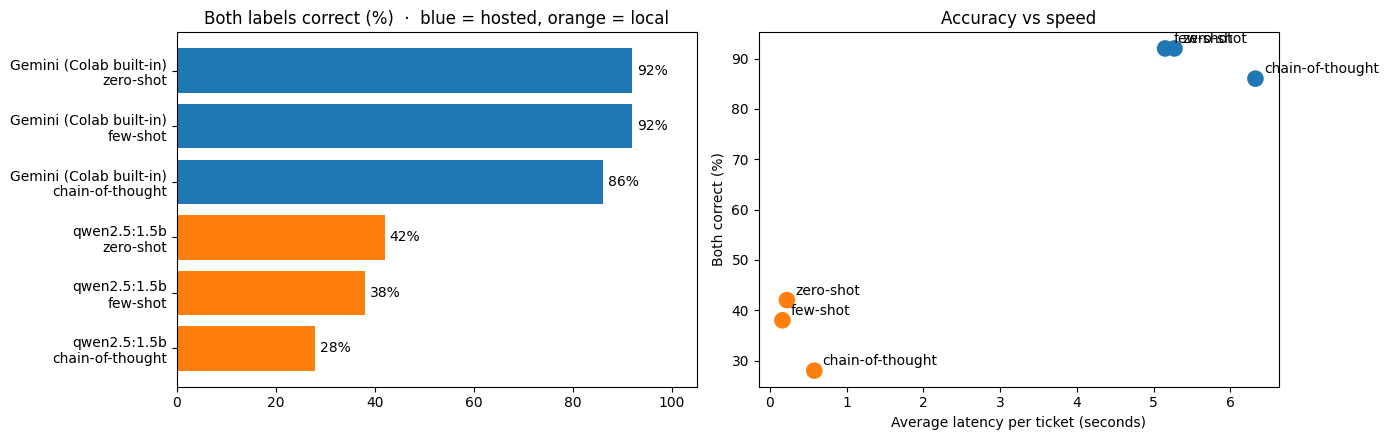

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
plot = summary.reset_index()
plot["label"] = plot["model"].str.replace(" (Ollama)", "", regex=False) + "\n" + plot["strategy"]
colors = ["tab:blue" if "Ollama" not in m else "tab:orange" for m in plot["model"]]
ax[0].barh(plot["label"], plot["both_acc"], color=colors)
for i, v in enumerate(plot["both_acc"]):
    ax[0].text(v + 1, i, f"{v:.0f}%", va="center")
ax[0].set_xlim(0, 105); ax[0].invert_yaxis()
ax[0].set_title("Both labels correct (%)  ·  blue = hosted, orange = local")

ax[1].scatter(plot["avg_latency_s"], plot["both_acc"], c=colors, s=120)
for _, r in plot.iterrows():
    ax[1].annotate(r["strategy"], (r["avg_latency_s"], r["both_acc"]), textcoords="offset points", xytext=(6, 4))
ax[1].set_xlabel("Average latency per ticket (seconds)"); ax[1].set_ylabel("Both correct (%)")
ax[1].set_title("Accuracy vs speed")
plt.tight_layout(); plt.show()

## 9. Failure cases
Wrong answers and invalid outputs, so we can see *why* the model fails (ambiguous tickets, hallucinated labels, format errors).

In [11]:
wrong = res[~res["both_ok"]][["model", "strategy", "ticket", "gold_urgency", "urgency",
                              "gold_department", "department", "valid", "reasoning"]]
print(f"Wrong or invalid answers: {len(wrong)} of {len(res)}")
print("\nTickets most often wrong across all runs:")
print(wrong["ticket"].value_counts().head(8).to_string())

print("\nOutputs that needed a retry or stayed invalid:")
fmt = res[(res["retries"] > 0) | (~res["valid"])][["model", "strategy", "retries", "valid", "errors", "raw"]]
print(fmt.head(10).to_string() if len(fmt) else "None: schema-constrained JSON mode prevented format errors.")
wrong.head(15)

Wrong or invalid answers: 111 of 300

Tickets most often wrong across all runs:
ticket
Please delete my account and all my personal data.                                          6
Your support agent was rude to me on the phone yesterday and I want to file a complaint.    6
Can I get a price quote for 500 licences for my company?                                    6
I need to change my delivery address before the order ships tomorrow.                       5
I cancelled my plan but was still billed this month.                                        4
The refund you approved two weeks ago still hasn't reached my account.                      4
Pages load a little slowly in the afternoons, about 5 seconds.                              4
Can you send me a copy of last month's invoice for my records?                              3

Outputs that needed a retry or stayed invalid:
None: schema-constrained JSON mode prevented format errors.


,model,strategy,ticket,gold_urgency,urgency,gold_department,department,valid,reasoning
23,Gemini (Colab built-in),zero-shot,Please delete my account and all my personal d...,medium,low,account,account,True,
31,Gemini (Colab built-in),zero-shot,I need to change my delivery address before th...,medium,high,shipping,shipping,True,
46,Gemini (Colab built-in),zero-shot,Your support agent was rude to me on the phone...,medium,low,general,general,True,
47,Gemini (Colab built-in),zero-shot,Can I get a price quote for 500 licences for m...,medium,low,general,billing,True,
73,Gemini (Colab built-in),few-shot,Please delete my account and all my personal d...,medium,low,account,account,True,
81,Gemini (Colab built-in),few-shot,I need to change my delivery address before th...,medium,high,shipping,shipping,True,
96,Gemini (Colab built-in),few-shot,Your support agent was rude to me on the phone...,medium,low,general,general,True,
97,Gemini (Colab built-in),few-shot,Can I get a price quote for 500 licences for m...,medium,low,general,general,True,
102,Gemini (Colab built-in),chain-of-thought,I cancelled my plan but was still billed this ...,medium,high,billing,billing,True,The customer was improperly charged after canc...
109,Gemini (Colab built-in),chain-of-thought,The refund you approved two weeks ago still ha...,medium,high,billing,billing,True,The customer needs the billing team to investi...


## 10. Conclusion (fill in after running)
- **Best overall:** ___ with ___ (both labels correct ___%).
- **Best accuracy-to-cost:** ___ (accuracy ___% at ~$___ per 1,000 tickets / free locally).
- **Prompting:** few-shot vs zero-shot ___; chain-of-thought ___ (more output tokens and latency; did it help?).
- **Hosted vs local:** hosted is ___ more accurate; local is free and private but ___ slower on CPU.
- **Structured output:** with JSON mode + Pydantic, invalid outputs = ___, retries = ___.
- **Failure cases:** most errors were on ___ (e.g. urgency of borderline tickets / department of overlapping topics like billing vs account).